1. 5개년 평균 데이터 생성
2. 데이터 표준화
3. K-Means 군집 분석
4. 군집 특성 분석
5. 지원 우선순위 점수 산출
6. 지원 우선순위 등급 분류
7. 시각화
   - 등급별 지역 분포
   - 지원 우선순위 TOP 10
   - 군집별 우선지원 지역 수
   - 군집별 우선지원 지역 비율

In [2]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 8.4/8.4 MB 47.9 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -------------- ------------------------- 13.1/37.4 MB 62.2 MB/s eta 0:00:01
   --------------------------- ------------ 26.0/37.4 MB 62.3 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 62.2 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 57.7 MB/s  0:00:00

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- -------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [5]:
df = pd.read_csv('../data/final/시군구_기후복지_통합데이터.csv')

df.head()

,시도,시군구,연도,고령인구,노인_1인가구,경도,위도,관측소_지점,관측소명,관측소_시도,...,여름관측일수,여름부족일수,여름관측_주의,한파일수,관측일수_y,겨울관측일수,겨울부족일수,겨울관측_주의,무더위쉼터_개수,한파쉼터_개수
0,강원특별자치도,강릉시,2021,47318,10813,128.883209,37.709604,105,강릉,강원특별자치도,...,122,0,False,4,365,151,0,False,193,202
1,강원특별자치도,고성군,2021,8236,2006,128.358361,38.401009,90,속초,강원특별자치도,...,122,0,False,7,365,151,0,False,28,28
2,강원특별자치도,동해시,2021,19039,4615,129.045397,37.515759,106,동해,강원특별자치도,...,122,0,False,2,365,151,0,False,157,157
3,강원특별자치도,삼척시,2021,16884,4335,129.173724,37.257882,216,태백,강원특별자치도,...,122,0,False,19,365,151,0,False,63,63
4,강원특별자치도,속초시,2021,16673,4313,128.515038,38.175014,90,속초,강원특별자치도,...,122,0,False,7,365,151,0,False,124,58


In [6]:
print(df.shape)
print(df.columns.tolist())
print(df['연도'].unique() if '연도' in df.columns else '연도 컬럼 없음')

(1145, 23)
['시도', '시군구', '연도', '고령인구', '노인_1인가구', '경도', '위도', '관측소_지점', '관측소명', '관측소_시도', '거리_km', '폭염일수', '관측일수_x', '여름관측일수', '여름부족일수', '여름관측_주의', '한파일수', '관측일수_y', '겨울관측일수', '겨울부족일수', '겨울관측_주의', '무더위쉼터_개수', '한파쉼터_개수']
[2021 2022 2023 2024 2025]


In [7]:
# 지역별 5개년 평균 계산 대상 컬럼
mean_cols = [
    '고령인구',
    '노인_1인가구',
    '거리_km',
    '폭염일수',
    '한파일수',
    '무더위쉼터_개수',
    '한파쉼터_개수'
]

# 지역별 5개년 평균 데이터 생성
df_mean = df.groupby(
    ['시도', '시군구']
)[mean_cols].mean().reset_index()

# 데이터 확인
print(df_mean.shape)
df_mean.head()


(229, 9)


,시도,시군구,고령인구,노인_1인가구,거리_km,폭염일수,한파일수,무더위쉼터_개수,한파쉼터_개수
0,강원특별자치도,강릉시,51961.0,12632.2,4.708752,25.2,1.2,193.0,202.0
1,강원특별자치도,고성군,8827.2,2256.8,24.547473,10.6,2.8,28.0,28.0
2,강원특별자치도,동해시,20936.2,5424.2,7.025810,10.2,0.6,157.0,157.0
3,강원특별자치도,삼척시,18105.0,4932.8,19.008927,4.8,20.4,63.0,63.0
4,강원특별자치도,속초시,18531.4,5043.0,9.488311,10.6,2.8,124.0,58.0


In [8]:
# 고령인구 1,000명당 쉼터 수
df_mean['무더위쉼터_비율'] = (
    df_mean['무더위쉼터_개수'] / df_mean['고령인구'] * 1000
)

df_mean['한파쉼터_비율'] = (
    df_mean['한파쉼터_개수'] / df_mean['고령인구'] * 1000
)

df_mean.head()

,시도,시군구,고령인구,노인_1인가구,거리_km,폭염일수,한파일수,무더위쉼터_개수,한파쉼터_개수,무더위쉼터_비율,한파쉼터_비율
0,강원특별자치도,강릉시,51961.0,12632.2,4.708752,25.2,1.2,193.0,202.0,3.714324,3.887531
1,강원특별자치도,고성군,8827.2,2256.8,24.547473,10.6,2.8,28.0,28.0,3.172014,3.172014
2,강원특별자치도,동해시,20936.2,5424.2,7.025810,10.2,0.6,157.0,157.0,7.498973,7.498973
3,강원특별자치도,삼척시,18105.0,4932.8,19.008927,4.8,20.4,63.0,63.0,3.479702,3.479702
4,강원특별자치도,속초시,18531.4,5043.0,9.488311,10.6,2.8,124.0,58.0,6.691346,3.129823


In [9]:
# K-Means 분석에 사용할 변수
feature_cols = [
    '노인_1인가구',
    '폭염일수',
    '한파일수',
    '무더위쉼터_비율',
    '한파쉼터_비율',
    '거리_km'
]

# 분석 데이터 구성
X = df_mean[feature_cols].copy()

# 데이터 확인
print(X.shape)
print(X.describe())

(229, 6)
            노인_1인가구        폭염일수        한파일수    무더위쉼터_비율     한파쉼터_비율  \
count    229.000000  229.000000  229.000000  229.000000  229.000000   
mean    9328.131878   21.024454    4.628821    9.891432    9.043784   
std     6664.135177    9.794973    5.732429    8.699031    8.581064   
min      605.400000    0.000000    0.000000    0.955842    0.287214   
25%     4380.600000   12.600000    0.800000    3.466832    2.386784   
50%     7591.000000   21.600000    2.800000    6.365969    5.767382   
75%    12538.200000   26.200000    5.400000   14.797630   14.020122   
max    41739.400000   42.800000   31.600000   37.404013   36.908595   

            거리_km  
count  229.000000  
mean    11.792598  
std      7.468898  
min      0.144519  
25%      5.552895  
50%     10.386506  
75%     17.059955  
max     30.556337  


In [10]:
# StandardScaler 객체 생성
scaler = StandardScaler()

# 데이터 표준화
X_scaled = scaler.fit_transform(X)

# 데이터프레임으로 변환
X_scaled = pd.DataFrame(
    X_scaled,
    columns=feature_cols,
    index=X.index
)

# 결과 확인
print(X_scaled.shape)
X_scaled.head()

(229, 6)


,노인_1인가구,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
0,0.496885,0.427229,-0.599455,-0.711647,-0.602204,-0.950524
1,-1.063427,-1.066597,-0.319730,-0.774125,-0.685770,1.711473
2,-0.587095,-1.107524,-0.704352,-0.275628,-0.180420,-0.639616
3,-0.660995,-1.660035,2.757248,-0.738677,-0.649834,0.968300
4,-0.644423,-1.066597,-0.319730,-0.368673,-0.690697,-0.309193


In [11]:
# 군집 개수별 평가 결과 저장
inertia = []
silhouette_scores = []

# K = 2~10까지 반복
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# 결과 출력
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.3065
K=3, Silhouette Score=0.3042
K=4, Silhouette Score=0.2363
K=5, Silhouette Score=0.2403
K=6, Silhouette Score=0.2327
K=7, Silhouette Score=0.2382
K=8, Silhouette Score=0.2338
K=9, Silhouette Score=0.2370
K=10, Silhouette Score=0.2339


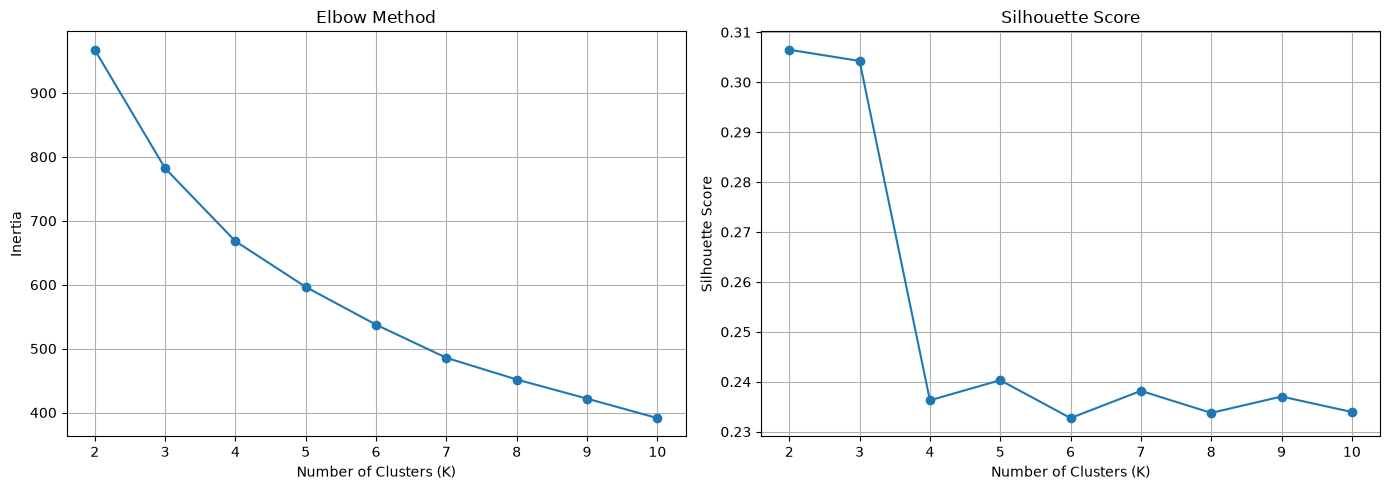

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(
    range(2, 11),
    inertia,
    marker='o'
)
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

# Silhouette Score
axes[1].plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [13]:
# K-Means 모델 생성
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# 군집 학습 및 라벨 생성
df_mean['군집'] = kmeans.fit_predict(X_scaled)

# 군집별 지역 개수 확인
print(df_mean['군집'].value_counts().sort_index())

군집
0     58
1    130
2     41
Name: count, dtype: int64


In [14]:
# 군집별 평균 특성 확인
cluster_result = df_mean.groupby('군집')[feature_cols].mean()

cluster_result

,노인_1인가구,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
군집,,,,,,
0,4692.931034,24.065517,2.717241,22.587394,21.409068,13.863439
1,12526.050769,20.984615,2.441538,4.787796,3.992045,9.572828
2,5745.502439,16.848780,14.268293,8.113553,7.569141,15.901409


In [15]:
# 군집별 주요 지역 확인

for cluster in sorted(df_mean['군집'].unique()):

    print(f"\n===== 군집 {cluster} =====")

    cluster_data = df_mean[
        df_mean['군집'] == cluster
    ]

    display(
        cluster_data[
            [
                '시도',
                '시군구',
                '노인_1인가구',
                '폭염일수',
                '한파일수',
                '무더위쉼터_비율',
                '한파쉼터_비율'
            ]
        ].sort_values(
            by='노인_1인가구',
            ascending=False
        ).head(10)
    )


===== 군집 0 =====


,시도,시군구,노인_1인가구,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
199,전북특별자치도,정읍시,8713.4,29.0,1.4,15.831184,14.020122
206,충청남도,논산시,8258.8,25.6,3.2,17.325409,15.512630
207,충청남도,당진시,7971.6,16.6,3.2,12.458776,12.458776
166,전남광주통합특별시,나주시,7397.6,26.2,0.4,21.963688,21.822669
189,전북특별자치도,김제시,7383.0,19.8,1.2,22.098187,22.133829
55,경상남도,사천시,7146.2,24.2,1.4,13.578978,12.955079
208,충청남도,보령시,6990.2,14.0,1.4,16.203154,15.050775
204,충청남도,공주시,6969.4,22.2,3.4,16.221685,15.014035
185,전남광주통합특별시,해남군,6476.8,18.4,1.2,25.590332,24.520502
190,전북특별자치도,남원시,6408.4,27.0,2.6,24.116219,22.264291



===== 군집 1 =====


,시도,시군구,노인_1인가구,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
61,경상남도,창원시,41739.4,25.2,0.8,5.365403,4.820608
30,경기도,수원시,32801.2,18.0,5.4,4.743600,3.810019
19,경기도,고양시,32451.2,21.6,4.2,1.439209,1.152514
29,경기도,성남시,30773.6,18.0,5.4,2.083789,2.083789
227,충청북도,청주시,30716.0,34.0,2.2,6.472434,6.346540
28,경기도,부천시,27256.0,7.4,2.8,3.701503,3.561406
198,전북특별자치도,전주시,26388.6,30.0,1.2,4.696478,3.702139
40,경기도,용인시,24855.0,18.0,5.4,1.473080,0.988042
88,경상북도,포항시,24659.2,25.2,0.4,6.428282,5.836078
91,대구광역시,달서구,22564.0,40.4,0.8,1.557147,1.557147



===== 군집 2 =====


,시도,시군구,노인_1인가구,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
42,경기도,의정부시,17730.0,12.6,16.0,0.955842,0.774353
44,경기도,파주시,14263.8,10.6,26.4,5.949849,5.266249
12,강원특별자치도,춘천시,13278.2,22.8,18.2,3.906916,2.542055
25,경기도,김포시,12227.6,4.4,10.0,2.209518,0.680921
212,충청남도,아산시,11585.0,15.8,10.4,12.941331,12.283298
228,충청북도,충주시,11400.0,23.4,12.4,10.108668,9.673664
22,경기도,광주시,9807.6,16.4,8.4,5.437831,4.632226
35,경기도,양주시,9033.2,12.6,16.0,6.878910,6.341495
224,충청북도,제천시,8472.2,10.8,23.0,4.084774,3.048780
33,경기도,안성시,7844.0,15.8,10.4,14.341011,14.315171


In [16]:
# 고령인구를 포함한 지역별 평균 데이터 생성
mean_cols = [
    '고령인구',
    '노인_1인가구',
    '거리_km',
    '폭염일수',
    '한파일수',
    '무더위쉼터_개수',
    '한파쉼터_개수'
]

df_mean = df.groupby(
    ['시도', '시군구']
)[mean_cols].mean().reset_index()

# 고령인구 대비 노인 1인 가구 비율
df_mean['노인_1인가구_비율'] = (
    df_mean['노인_1인가구'] / df_mean['고령인구'] * 100
)

# 쉼터 공급 비율
df_mean['무더위쉼터_비율'] = (
    df_mean['무더위쉼터_개수'] /
    df_mean['고령인구'] * 1000
)

df_mean['한파쉼터_비율'] = (
    df_mean['한파쉼터_개수'] /
    df_mean['고령인구'] * 1000
)

df_mean.head()

,시도,시군구,고령인구,노인_1인가구,거리_km,폭염일수,한파일수,무더위쉼터_개수,한파쉼터_개수,노인_1인가구_비율,무더위쉼터_비율,한파쉼터_비율
0,강원특별자치도,강릉시,51961.0,12632.2,4.708752,25.2,1.2,193.0,202.0,24.310926,3.714324,3.887531
1,강원특별자치도,고성군,8827.2,2256.8,24.547473,10.6,2.8,28.0,28.0,25.566431,3.172014,3.172014
2,강원특별자치도,동해시,20936.2,5424.2,7.025810,10.2,0.6,157.0,157.0,25.908235,7.498973,7.498973
3,강원특별자치도,삼척시,18105.0,4932.8,19.008927,4.8,20.4,63.0,63.0,27.245512,3.479702,3.479702
4,강원특별자치도,속초시,18531.4,5043.0,9.488311,10.6,2.8,124.0,58.0,27.213270,6.691346,3.129823


In [17]:
# 개선된 K-Means 분석 변수
feature_cols = [
    '노인_1인가구_비율',
    '폭염일수',
    '한파일수',
    '무더위쉼터_비율',
    '한파쉼터_비율',
    '거리_km'
]

# 분석 데이터 구성
X = df_mean[feature_cols].copy()

# 데이터 확인
print(X.shape)
X.describe()

(229, 6)


,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
count,229.000000,229.000000,229.000000,229.000000,229.000000,229.000000
mean,23.315267,21.024454,4.628821,9.891432,9.043784,11.792598
std,3.602195,9.794973,5.732429,8.699031,8.581064,7.468898
min,13.224655,0.000000,0.000000,0.955842,0.287214,0.144519
25%,20.890556,12.600000,0.800000,3.466832,2.386784,5.552895
50%,23.435435,21.600000,2.800000,6.365969,5.767382,10.386506
75%,26.028970,26.200000,5.400000,14.797630,14.020122,17.059955
max,31.826319,42.800000,31.600000,37.404013,36.908595,30.556337


In [18]:
# StandardScaler 적용
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=feature_cols,
    index=X.index
)

X_scaled.head()

,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
0,0.277009,0.427229,-0.599455,-0.711647,-0.602204,-0.950524
1,0.626311,-1.066597,-0.319730,-0.774125,-0.685770,1.711473
2,0.721407,-1.107524,-0.704352,-0.275628,-0.180420,-0.639616
3,1.093460,-1.660035,2.757248,-0.738677,-0.649834,0.968300
4,1.084489,-1.066597,-0.319730,-0.368673,-0.690697,-0.309193


In [19]:
inertia = []
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.3261
K=3, Silhouette Score=0.3178
K=4, Silhouette Score=0.2421
K=5, Silhouette Score=0.2571
K=6, Silhouette Score=0.2550
K=7, Silhouette Score=0.2600
K=8, Silhouette Score=0.2625
K=9, Silhouette Score=0.2662
K=10, Silhouette Score=0.2399


In [20]:
# K=2 모델
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df_mean['군집_K2'] = kmeans_2.fit_predict(X_scaled)


# K=3 모델
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_mean['군집_K3'] = kmeans_3.fit_predict(X_scaled)


# 군집별 지역 수 비교
print("===== K=2 =====")
print(df_mean['군집_K2'].value_counts().sort_index())

print("\n===== K=3 =====")
print(df_mean['군집_K3'].value_counts().sort_index())

===== K=2 =====
군집_K2
0     63
1    166
Name: count, dtype: int64

===== K=3 =====
군집_K3
0     32
1     58
2    139
Name: count, dtype: int64


In [21]:
# K=2 군집별 평균
print("===== K=2 군집 특성 =====")

display(
    df_mean.groupby('군집_K2')[feature_cols].mean().round(2)
)


# K=3 군집별 평균
print("===== K=3 군집 특성 =====")

display(
    df_mean.groupby('군집_K3')[feature_cols].mean().round(2)
)

===== K=2 군집 특성 =====


,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
군집_K2,,,,,,
0,26.42,24.74,3.78,21.98,20.87,13.78
1,22.14,19.61,4.95,5.30,4.56,11.04


===== K=3 군집 특성 =====


,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율,거리_km
군집_K3,,,,,,
0,24.19,17.74,16.32,8.38,7.83,15.80
1,26.41,24.29,2.78,22.62,21.44,13.56
2,21.82,20.42,2.71,4.93,4.15,10.13


In [22]:
# 최종 K-Means 모델
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# 군집 결과 저장
df_mean['군집'] = kmeans.fit_predict(X_scaled)

# 군집별 지역 수 확인
print(df_mean['군집'].value_counts().sort_index())

군집
0     32
1     58
2    139
Name: count, dtype: int64


c:\Users\expri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\expri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\expri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\expri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\expri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\e

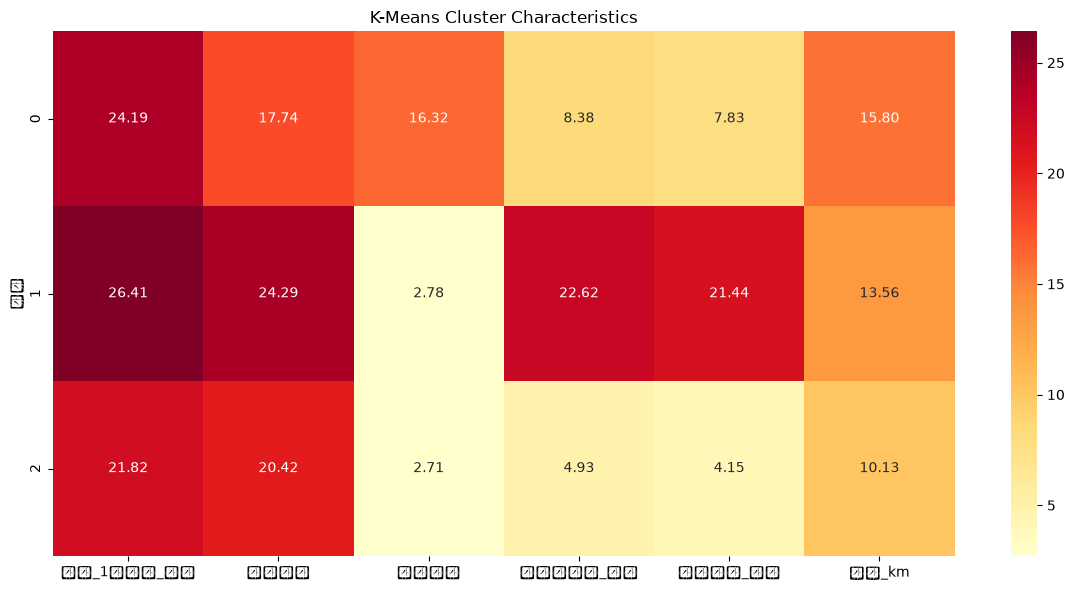

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_mean = df_mean.groupby('군집')[feature_cols].mean()

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_mean,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('K-Means Cluster Characteristics')
plt.tight_layout()
plt.show()

In [24]:
for cluster_num in sorted(df_mean['군집'].unique()):
    print(f"\n===== 군집 {cluster_num} =====")

    regions = df_mean[df_mean['군집'] == cluster_num][
        ['시도', '시군구']
    ]

    print(regions.to_string(index=False))


===== 군집 0 =====
     시도  시군구
강원특별자치도  삼척시
강원특별자치도  양구군
강원특별자치도  영월군
강원특별자치도  인제군
강원특별자치도  정선군
강원특별자치도  철원군
강원특별자치도  춘천시
강원특별자치도  태백시
강원특별자치도  평창군
강원특별자치도  홍천군
강원특별자치도  화천군
    경기도  가평군
    경기도 동두천시
    경기도  안성시
    경기도  양주시
    경기도  여주시
    경기도  연천군
    경기도 의정부시
    경기도  파주시
    경기도  포천시
   경상북도  봉화군
   경상북도  영양군
   경상북도  청송군
   충청남도  아산시
   충청북도  괴산군
   충청북도  단양군
   충청북도  보은군
   충청북도  옥천군
   충청북도  음성군
   충청북도  제천시
   충청북도  진천군
   충청북도  충주시

===== 군집 1 =====
       시도 시군구
     경상남도 거창군
     경상남도 고성군
     경상남도 남해군
     경상남도 사천시
     경상남도 산청군
     경상남도 의령군
     경상남도 창녕군
     경상남도 하동군
     경상남도 함안군
     경상남도 함양군
     경상남도 합천군
     경상북도 고령군
     경상북도 성주군
     경상북도 안동시
     경상북도 영덕군
     경상북도 예천군
     경상북도 의성군
     경상북도 청도군
     경상북도 칠곡군
    대구광역시 군위군
전남광주통합특별시 강진군
전남광주통합특별시 곡성군
전남광주통합특별시 구례군
전남광주통합특별시 나주시
전남광주통합특별시 담양군
전남광주통합특별시 무안군
전남광주통합특별시 보성군
전남광주통합특별시 신안군
전남광주통합특별시 영광군
전남광주통합특별시 영암군
전남광주통합특별시 장성군
전남광주통합특별시 장흥군
전남광주통합특별시 진도군
전남광주통합특별시 함평군
전남광주통합특별시 해남군
전남광주통합특별시 화순군
  전북특별자치도 고창군
  전

In [25]:
from sklearn.preprocessing import MinMaxScaler

# 지원 우선순위 평가 항목
priority_cols = [
    '노인_1인가구_비율',
    '폭염일수',
    '한파일수',
    '무더위쉼터_비율',
    '한파쉼터_비율'
]

# 0~1 정규화
scaler = MinMaxScaler()

df_priority = df_mean.copy()

df_priority[priority_cols] = scaler.fit_transform(
    df_priority[priority_cols]
)

df_priority[priority_cols].head()

,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
0,0.595983,0.588785,0.037975,0.075682,0.098312
1,0.663477,0.247664,0.088608,0.060803,0.078774
2,0.681852,0.238318,0.018987,0.179519,0.196928
3,0.753742,0.112150,0.645570,0.069245,0.087176
4,0.752009,0.247664,0.088608,0.157361,0.077622


In [26]:
# 쉼터 비율 역방향 변환
df_priority['무더위쉼터_취약도'] = (
    1 - df_priority['무더위쉼터_비율']
)

df_priority['한파쉼터_취약도'] = (
    1 - df_priority['한파쉼터_비율']
)

# 최종 취약도 평가 항목
vulnerability_cols = [
    '노인_1인가구_비율',
    '폭염일수',
    '한파일수',
    '무더위쉼터_취약도',
    '한파쉼터_취약도'
]

df_priority[vulnerability_cols].head()

,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_취약도,한파쉼터_취약도
0,0.595983,0.588785,0.037975,0.924318,0.901688
1,0.663477,0.247664,0.088608,0.939197,0.921226
2,0.681852,0.238318,0.018987,0.820481,0.803072
3,0.753742,0.112150,0.645570,0.930755,0.912824
4,0.752009,0.247664,0.088608,0.842639,0.922378


In [27]:
# 평가 항목별 가중치
weights = {
    '노인_1인가구_비율': 0.20,
    '폭염일수': 0.25,
    '한파일수': 0.25,
    '무더위쉼터_취약도': 0.15,
    '한파쉼터_취약도': 0.15
}

# 종합 지원 우선순위 점수 계산
df_priority['지원_우선순위_점수'] = sum(
    df_priority[col] * weight
    for col, weight in weights.items()
) * 100

# 점수가 높은 순서대로 정렬
df_priority = df_priority.sort_values(
    by='지원_우선순위_점수',
    ascending=False
).reset_index(drop=True)

# 우선순위 상위 20개 지역 확인
df_priority[
    ['시도', '시군구', '군집', '지원_우선순위_점수']
].head(20)

,시도,시군구,군집,지원_우선순위_점수
0,강원특별자치도,정선군,0,75.855059
1,강원특별자치도,평창군,0,75.307408
2,경상북도,영양군,0,68.880152
3,대구광역시,남구,2,68.452056
4,강원특별자치도,홍천군,0,67.054053
5,대구광역시,서구,2,66.858481
6,경상북도,청송군,0,66.830930
7,대구광역시,동구,2,65.720190
8,강원특별자치도,춘천시,0,65.716200
9,강원특별자치도,화천군,0,65.560167


In [28]:
# 지원 우선순위 4개 등급 분류
df_priority['지원_우선순위_등급'] = pd.qcut(
    df_priority['지원_우선순위_점수'].rank(method='first'),
    q=4,
    labels=['일반', '관심', '주의', '우선지원']
)

# 등급별 지역 수 확인
print(df_priority['지원_우선순위_등급'].value_counts())

# 등급별 점수 범위 확인
grade_summary = df_priority.groupby(
    '지원_우선순위_등급',
    observed=False
)['지원_우선순위_점수'].agg(
    ['count', 'min', 'max', 'mean']
)

grade_summary

지원_우선순위_등급
일반      58
관심      57
주의      57
우선지원    57
Name: count, dtype: int64


,count,min,max,mean
지원_우선순위_등급,,,,
일반,58,24.130554,44.001314,38.487780
관심,57,44.074201,49.433203,46.999399
주의,57,49.445207,54.710736,51.696861
우선지원,57,54.726833,75.855059,61.120790


In [29]:
# 우선지원 지역 확인
top_priority = df_priority[
    df_priority['지원_우선순위_등급'] == '우선지원'
].sort_values(
    by='지원_우선순위_점수',
    ascending=False
)

top_priority[
    [
        '시도',
        '시군구',
        '군집',
        '지원_우선순위_점수',
        '지원_우선순위_등급'
    ]
]

,시도,시군구,군집,지원_우선순위_점수,지원_우선순위_등급
0,강원특별자치도,정선군,0,75.855059,우선지원
1,강원특별자치도,평창군,0,75.307408,우선지원
2,경상북도,영양군,0,68.880152,우선지원
3,대구광역시,남구,2,68.452056,우선지원
4,강원특별자치도,홍천군,0,67.054053,우선지원
5,대구광역시,서구,2,66.858481,우선지원
6,경상북도,청송군,0,66.830930,우선지원
7,대구광역시,동구,2,65.720190,우선지원
8,강원특별자치도,춘천시,0,65.716200,우선지원
9,강원특별자치도,화천군,0,65.560167,우선지원


In [30]:
# 우선지원 상위 10개 지역의 원본 지표 확인
top10_detail = top_priority.head(10)[
    ['시도', '시군구', '군집', '지원_우선순위_점수']
].merge(
    df_mean[
        [
            '시도', '시군구',
            '노인_1인가구_비율',
            '폭염일수',
            '한파일수',
            '무더위쉼터_비율',
            '한파쉼터_비율'
        ]
    ],
    on=['시도', '시군구'],
    how='left'
)

top10_detail

,시도,시군구,군집,지원_우선순위_점수,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
0,강원특별자치도,정선군,0,75.855059,27.138378,31.6,19.6,4.403579,4.315508
1,강원특별자치도,평창군,0,75.307408,25.949386,31.6,19.6,3.469761,3.469761
2,경상북도,영양군,0,68.880152,28.830429,33.6,14.8,11.943772,11.790647
3,대구광역시,남구,2,68.452056,26.954782,40.4,0.8,1.390237,1.172160
4,강원특별자치도,홍천군,0,67.054053,24.453980,21.2,19.2,3.802888,3.755939
5,대구광역시,서구,2,66.858481,25.573965,40.4,0.8,2.176389,0.648286
6,경상북도,청송군,0,66.830930,27.227408,33.6,14.8,12.214499,12.313803
7,대구광역시,동구,2,65.720190,24.172722,40.4,0.8,1.282201,0.647576
8,강원특별자치도,춘천시,0,65.716200,22.653632,22.8,18.2,3.906916,2.542055
9,강원특별자치도,화천군,0,65.560167,25.615060,23.8,26.4,16.553067,15.254787


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 등급별 지역 수 집계
grade_counts = (
    df_priority['지원_우선순위_등급']
    .value_counts()
    .reindex(['일반', '관심', '주의', '우선지원'])
)

print(grade_counts)

지원_우선순위_등급
일반      58
관심      57
주의      57
우선지원    57
Name: count, dtype: int64


C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 49900 (\N{HANGUL SYLLABLE SIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_28800\3065075999.py:15: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from 

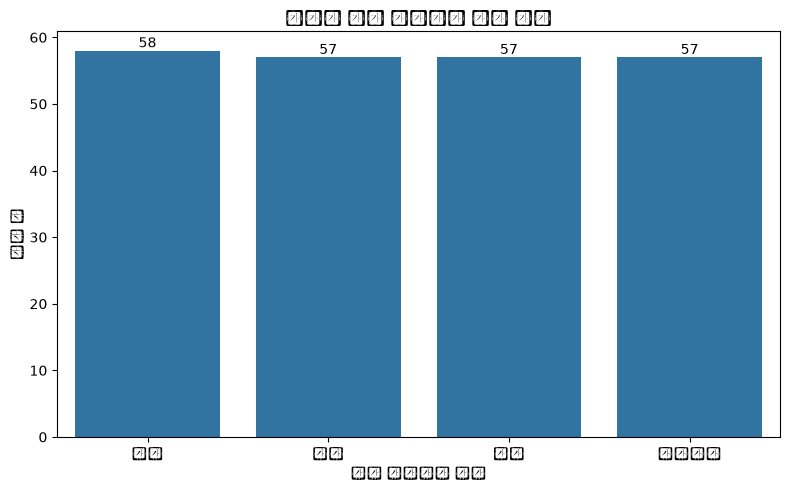

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=grade_counts.index,
    y=grade_counts.values
)

plt.title('지역별 지원 우선순위 등급 분포')
plt.xlabel('지원 우선순위 등급')
plt.ylabel('지역 수')

for i, value in enumerate(grade_counts.values):
    plt.text(i, value + 0.5, str(value), ha='center')

plt.tight_layout()
plt.show()

In [33]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

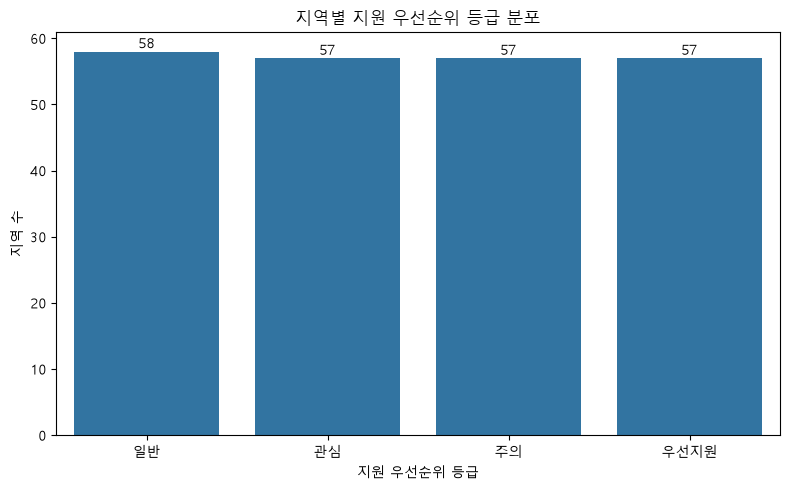

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=grade_counts.index,
    y=grade_counts.values
)

plt.title('지역별 지원 우선순위 등급 분포')
plt.xlabel('지원 우선순위 등급')
plt.ylabel('지역 수')

for i, value in enumerate(grade_counts.values):
    plt.text(i, value + 0.5, str(value), ha='center')

plt.tight_layout()
plt.show()

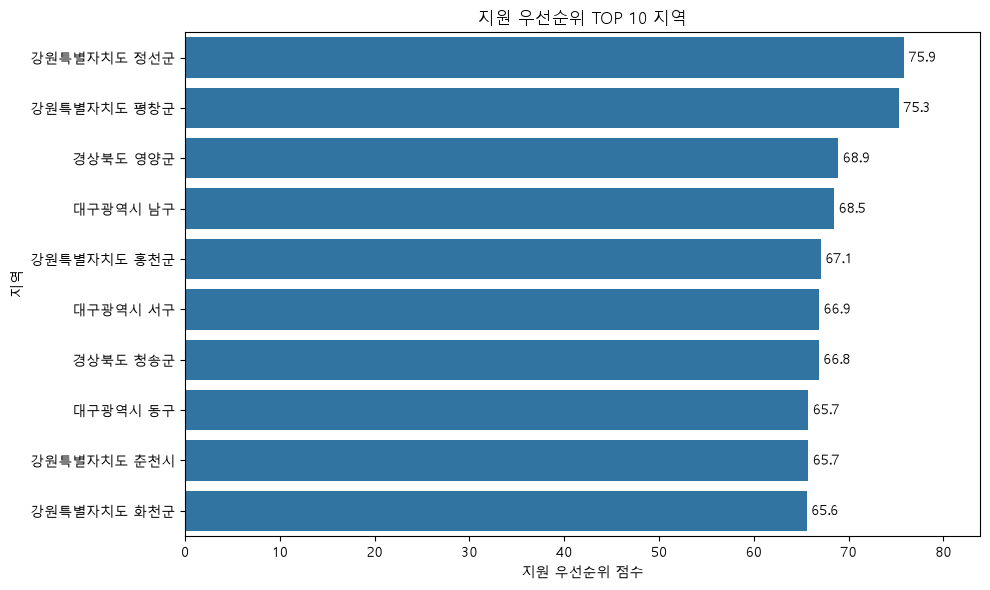

In [35]:
# 지원 우선순위 TOP 10
top10 = df_priority.head(10).copy()

# 지역명 생성
top10['지역명'] = top10['시도'] + ' ' + top10['시군구']

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10,
    x='지원_우선순위_점수',
    y='지역명'
)

plt.title('지원 우선순위 TOP 10 지역')
plt.xlabel('지원 우선순위 점수')
plt.ylabel('지역')

for i, value in enumerate(top10['지원_우선순위_점수']):
    plt.text(value + 0.5, i, f'{value:.1f}', va='center')

plt.xlim(0, top10['지원_우선순위_점수'].max() + 8)
plt.tight_layout()
plt.show()

In [36]:
# 우선지원 등급만 추출
priority_cluster = df_priority[
    df_priority['지원_우선순위_등급'] == '우선지원'
]

# 군집별 지역 수 집계
cluster_counts = (
    priority_cluster['군집']
    .value_counts()
    .sort_index()
)

print(cluster_counts)

군집
0    21
1     8
2    28
Name: count, dtype: int64


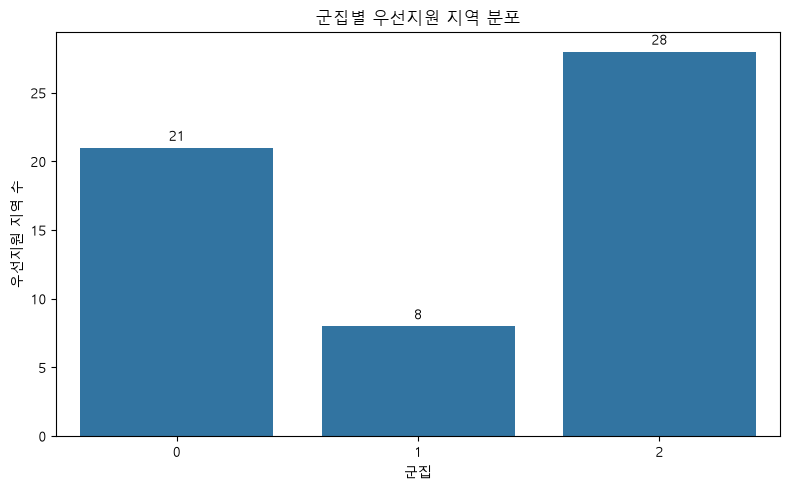

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title('군집별 우선지원 지역 분포')
plt.xlabel('군집')
plt.ylabel('우선지원 지역 수')

for i, value in enumerate(cluster_counts.values):
    plt.text(i, value + 0.5, str(value), ha='center')

plt.tight_layout()
plt.show()

In [38]:
# 군집별 전체 지역 수
total_counts = df_priority['군집'].value_counts().sort_index()

# 군집별 우선지원 지역 비율
priority_ratio = (
    cluster_counts / total_counts * 100
)

print('군집별 우선지원 지역 비율')
print(priority_ratio.round(2))

군집별 우선지원 지역 비율
군집
0    65.62
1    13.79
2    20.14
Name: count, dtype: float64


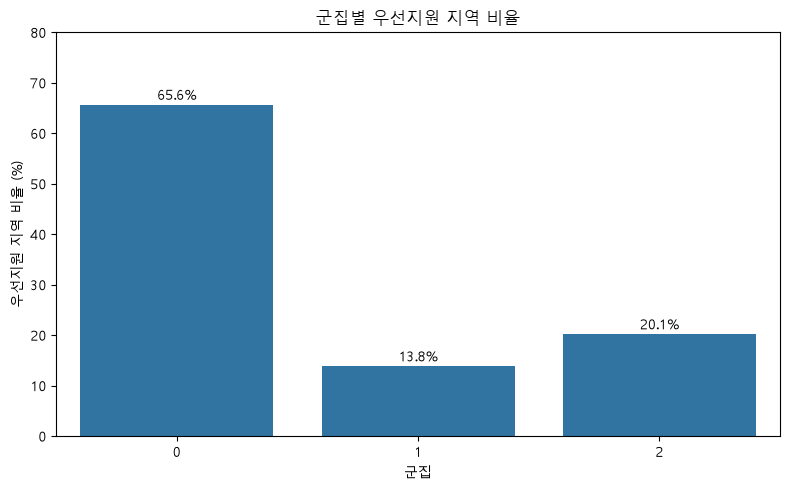

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=priority_ratio.index.astype(str),
    y=priority_ratio.values
)

plt.title('군집별 우선지원 지역 비율')
plt.xlabel('군집')
plt.ylabel('우선지원 지역 비율 (%)')

for i, value in enumerate(priority_ratio.values):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.ylim(0, 80)
plt.tight_layout()
plt.show()

8. 전국 시군구 지도 시각화

In [44]:
import geopandas as gpd
import os

boundary_path = '../data/raw/행정구역경계_2025'

shp_files = [
    f for f in os.listdir(boundary_path)
    if f.lower().endswith('.shp')
]

print("SHP 파일 목록:")
for file in shp_files:
    print(file)

SHP 파일 목록:
bnd_sigungu_00_2025_2Q.shp


In [45]:
# 시군구 행정구역 경계 데이터 불러오기
shp_path = os.path.join(
    boundary_path,
    'bnd_sigungu_00_2025_2Q.shp'
)

gdf = gpd.read_file(shp_path)

print("데이터 크기:", gdf.shape)
print("\n컬럼 목록:")
print(gdf.columns.tolist())

print("\n상위 5개 데이터:")
display(gdf.head())

데이터 크기: (252, 4)

컬럼 목록:
['BASE_DATE', 'SIGUNGU_CD', 'SIGUNGU_NM', 'geometry']

상위 5개 데이터:


,BASE_DATE,SIGUNGU_CD,SIGUNGU_NM,geometry
0,20250630,11010,종로구,"POLYGON ((953683.828 1959209.871, 953665.283 1..."
1,20250630,11020,중구,"POLYGON ((957890.386 1952616.746, 957909.908 1..."
2,20250630,11030,용산구,"POLYGON ((953114.222 1950746.999, 953114.218 1..."
3,20250630,11040,성동구,"POLYGON ((959381.838 1952723.894, 959416.042 1..."
4,20250630,11050,광진구,"POLYGON ((964825.058 1952633.25, 964875.581 19..."


In [46]:
# 행정구역 경계 지역 목록
print("행정구역 경계 지역 수:", gdf['SIGUNGU_NM'].nunique())

# 분석 데이터 지역 목록
print("분석 데이터 지역 수:", df_priority['시군구'].nunique())

# 경계 데이터에만 있는 지역
boundary_names = set(gdf['SIGUNGU_NM'].unique())
priority_names = set(df_priority['시군구'].unique())

print("\n경계 데이터에만 있는 지역:")
print(sorted(boundary_names - priority_names))

print("\n분석 데이터에만 있는 지역:")
print(sorted(priority_names - boundary_names))

행정구역 경계 지역 수: 230
분석 데이터 지역 수: 207

경계 데이터에만 있는 지역:
['고양시 덕양구', '고양시 일산동구', '고양시 일산서구', '부천시 소사구', '부천시 오정구', '부천시 원미구', '성남시 분당구', '성남시 수정구', '성남시 중원구', '수원시 권선구', '수원시 영통구', '수원시 장안구', '수원시 팔달구', '안산시 단원구', '안산시 상록구', '안양시 동안구', '안양시 만안구', '용인시 기흥구', '용인시 수지구', '용인시 처인구', '전주시 덕진구', '전주시 완산구', '창원시 마산합포구', '창원시 마산회원구', '창원시 성산구', '창원시 의창구', '창원시 진해구', '천안시 동남구', '천안시 서북구', '청주시 상당구', '청주시 서원구', '청주시 청원구', '청주시 흥덕구', '포항시 남구', '포항시 북구']

분석 데이터에만 있는 지역:
['고양시', '부천시', '성남시', '수원시', '안산시', '안양시', '용인시', '전주시', '창원시', '천안시', '청주시', '포항시']


In [47]:
# 분석 데이터의 시도별 시군구 수
print("시도별 분석 지역 수")

print(
    df_priority.groupby('시도')['시군구']
    .nunique()
    .sort_values(ascending=False)
)

# 분석 데이터의 중복 지역명 확인
print("\n중복 시군구 이름")

print(
    df_priority[
        df_priority['시군구'].duplicated(keep=False)
    ][['시도', '시군구']]
    .sort_values('시군구')
)

시도별 분석 지역 수
시도
경기도          31
전남광주통합특별시    27
서울특별시        25
경상북도         22
경상남도         18
강원특별자치도      18
부산광역시        16
충청남도         15
전북특별자치도      14
충청북도         11
인천광역시        10
대구광역시         9
대전광역시         5
울산광역시         5
제주특별자치도       2
세종특별자치시       1
Name: 시군구, dtype: int64

중복 시군구 이름
            시도  시군구
114      부산광역시  강서구
63       서울특별시  강서구
219       경상남도  고성군
111    강원특별자치도  고성군
178      부산광역시   남구
176      울산광역시   남구
101  전남광주통합특별시   남구
3        대구광역시   남구
112      부산광역시   동구
7        대구광역시   동구
171      울산광역시   동구
161      인천광역시   동구
95   전남광주통합특별시   동구
29       대전광역시   동구
205      울산광역시   북구
15       대구광역시   북구
12       부산광역시   북구
59   전남광주통합특별시   북구
110      부산광역시   서구
5        대구광역시   서구
195      인천광역시   서구
72   전남광주통합특별시   서구
46       대전광역시   서구
81       부산광역시   중구
20       대구광역시   중구
34       대전광역시   중구
148      울산광역시   중구
154      인천광역시   중구
62       서울특별시   중구


In [48]:
# 경계 데이터의 시군구 코드 앞 2자리로 시도별 분류
gdf['SIDO_CD'] = gdf['SIGUNGU_CD'].astype(str).str[:2]

print(
    gdf.groupby('SIDO_CD')['SIGUNGU_NM']
    .count()
)

print("\n전체 경계 지역 목록")

display(
    gdf[['SIGUNGU_CD', 'SIGUNGU_NM']]
    .sort_values('SIGUNGU_CD')
    .reset_index(drop=True)
)

SIDO_CD
11    25
21    16
22     9
23    10
24     5
25     5
26     5
29     1
31    44
32    18
33    14
34    16
35    15
36    22
37    23
38    22
39     2
Name: SIGUNGU_NM, dtype: int64

전체 경계 지역 목록


,SIGUNGU_CD,SIGUNGU_NM
0,11010,종로구
1,11020,중구
2,11030,용산구
3,11040,성동구
4,11050,광진구
...,...,...
247,38580,함양군
248,38590,거창군
249,38600,합천군
250,39010,제주시


In [49]:
gdf[gdf['SIDO_CD'] == '31'][
    ['SIGUNGU_CD', 'SIGUNGU_NM']
].sort_values('SIGUNGU_CD').reset_index(drop=True)

,SIGUNGU_CD,SIGUNGU_NM
0,31011,수원시 장안구
1,31012,수원시 권선구
2,31013,수원시 팔달구
3,31014,수원시 영통구
4,31021,성남시 수정구
5,31022,성남시 중원구
6,31023,성남시 분당구
7,31030,의정부시
8,31041,안양시 만안구
9,31042,안양시 동안구


In [50]:
# 구 단위 경계를 기존 시 단위로 변경
merge_names = {
    '수원시 장안구': '수원시',
    '수원시 권선구': '수원시',
    '수원시 팔달구': '수원시',
    '수원시 영통구': '수원시',

    '성남시 수정구': '성남시',
    '성남시 중원구': '성남시',
    '성남시 분당구': '성남시',

    '안양시 만안구': '안양시',
    '안양시 동안구': '안양시',

    '부천시 원미구': '부천시',
    '부천시 소사구': '부천시',
    '부천시 오정구': '부천시',

    '안산시 상록구': '안산시',
    '안산시 단원구': '안산시',

    '고양시 덕양구': '고양시',
    '고양시 일산동구': '고양시',
    '고양시 일산서구': '고양시',

    '용인시 처인구': '용인시',
    '용인시 기흥구': '용인시',
    '용인시 수지구': '용인시'
}

gdf['시군구_통합'] = gdf['SIGUNGU_NM'].replace(merge_names)

# 시군구 단위로 실제 경계 병합
gdf_merged = gdf.dissolve(
    by=['SIDO_CD', '시군구_통합'],
    as_index=False
)

print('기존 경계 수:', len(gdf))
print('통합 후 경계 수:', len(gdf_merged))

display(
    gdf_merged[['SIDO_CD', '시군구_통합']]
    .sort_values(['SIDO_CD', '시군구_통합'])
    .reset_index(drop=True)
)

기존 경계 수: 252
통합 후 경계 수: 239


,SIDO_CD,시군구_통합
0,11,강남구
1,11,강동구
2,11,강북구
3,11,강서구
4,11,관악구
...,...,...
234,38,함안군
235,38,함양군
236,38,합천군
237,39,서귀포시


In [51]:
# 분석 데이터와 경계 데이터의 지역 조합
priority_regions = set(
    zip(df_priority['시도'], df_priority['시군구'])
)

boundary_regions = set(
    zip(gdf_merged['SIDO_CD'], gdf_merged['시군구_통합'])
)

print('분석 데이터 지역 수:', len(priority_regions))
print('경계 데이터 지역 수:', len(boundary_regions))

print('\n분석 데이터에만 있는 지역:')
print(sorted(priority_regions - boundary_regions))

print('\n경계 데이터에만 있는 지역:')
print(sorted(boundary_regions - priority_regions))

분석 데이터 지역 수: 229
경계 데이터 지역 수: 239

분석 데이터에만 있는 지역:
[('강원특별자치도', '강릉시'), ('강원특별자치도', '고성군'), ('강원특별자치도', '동해시'), ('강원특별자치도', '삼척시'), ('강원특별자치도', '속초시'), ('강원특별자치도', '양구군'), ('강원특별자치도', '양양군'), ('강원특별자치도', '영월군'), ('강원특별자치도', '원주시'), ('강원특별자치도', '인제군'), ('강원특별자치도', '정선군'), ('강원특별자치도', '철원군'), ('강원특별자치도', '춘천시'), ('강원특별자치도', '태백시'), ('강원특별자치도', '평창군'), ('강원특별자치도', '홍천군'), ('강원특별자치도', '화천군'), ('강원특별자치도', '횡성군'), ('경기도', '가평군'), ('경기도', '고양시'), ('경기도', '과천시'), ('경기도', '광명시'), ('경기도', '광주시'), ('경기도', '구리시'), ('경기도', '군포시'), ('경기도', '김포시'), ('경기도', '남양주시'), ('경기도', '동두천시'), ('경기도', '부천시'), ('경기도', '성남시'), ('경기도', '수원시'), ('경기도', '시흥시'), ('경기도', '안산시'), ('경기도', '안성시'), ('경기도', '안양시'), ('경기도', '양주시'), ('경기도', '양평군'), ('경기도', '여주시'), ('경기도', '연천군'), ('경기도', '오산시'), ('경기도', '용인시'), ('경기도', '의왕시'), ('경기도', '의정부시'), ('경기도', '이천시'), ('경기도', '파주시'), ('경기도', '평택시'), ('경기도', '포천시'), ('경기도', '하남시'), ('경기도', '화성시'), ('경상남도', '거제시'), ('경상남도', '거창군'), ('경상남도', '고성군'), ('경상남도', '김해시'), ('경상남도', '남해군'), ('경상

In [52]:
merge_names.update({
    '청주시 상당구': '청주시',
    '청주시 서원구': '청주시',
    '청주시 청원구': '청주시',
    '청주시 흥덕구': '청주시',

    '천안시 동남구': '천안시',
    '천안시 서북구': '천안시',

    '전주시 덕진구': '전주시',
    '전주시 완산구': '전주시',

    '포항시 남구': '포항시',
    '포항시 북구': '포항시',

    '창원시 마산합포구': '창원시',
    '창원시 마산회원구': '창원시',
    '창원시 성산구': '창원시',
    '창원시 의창구': '창원시',
    '창원시 진해구': '창원시'
})

In [53]:
sido_mapping = {
    '11': '서울특별시',
    '21': '부산광역시',
    '22': '대구광역시',
    '23': '인천광역시',
    '24': '전남광주통합특별시',
    '25': '대전광역시',
    '26': '울산광역시',
    '29': '세종특별자치시',
    '31': '경기도',
    '32': '강원특별자치도',
    '33': '충청북도',
    '34': '충청남도',
    '35': '전북특별자치도',
    '36': '전남광주통합특별시',
    '37': '경상북도',
    '38': '경상남도',
    '39': '제주특별자치도'
}

gdf['시도'] = gdf['SIDO_CD'].map(sido_mapping)
gdf['시군구_통합'] = gdf['SIGUNGU_NM'].replace(merge_names)

gdf_merged = gdf.dissolve(
    by=['시도', '시군구_통합'],
    as_index=False
)

print('통합 후 경계 수:', len(gdf_merged))

통합 후 경계 수: 229


In [54]:
print('분석 데이터 지역 수:', len(df_priority))
print('경계 데이터 지역 수:', len(gdf_merged))

priority_regions = set(
    zip(df_priority['시도'], df_priority['시군구'])
)

boundary_regions = set(
    zip(gdf_merged['시도'], gdf_merged['시군구_통합'])
)

print('\n분석 데이터에만 있는 지역:')
print(sorted(priority_regions - boundary_regions))

print('\n경계 데이터에만 있는 지역:')
print(sorted(boundary_regions - priority_regions))

분석 데이터 지역 수: 229
경계 데이터 지역 수: 229

분석 데이터에만 있는 지역:
[]

경계 데이터에만 있는 지역:
[]


In [57]:
gdf_map = gdf_merged.merge(
    df_priority,
    left_on=['시도', '시군구_통합'],
    right_on=['시도', '시군구'],
    how='left'
)

print('지도 데이터 크기:', gdf_map.shape)
print('등급 결측치:', gdf_map['지원_우선순위_등급'].isna().sum())
print('점수 결측치:', gdf_map['지원_우선순위_점수'].isna().sum())

지도 데이터 크기: (229, 25)
등급 결측치: 0
점수 결측치: 0


In [58]:
display(
    gdf_map[
        ['시도', '시군구_통합',
         '지원_우선순위_점수', '지원_우선순위_등급']
    ].head(10)
)

,시도,시군구_통합,지원_우선순위_점수,지원_우선순위_등급
0,강원특별자치도,강릉시,54.978735,우선지원
1,강원특별자치도,고성군,49.582664,주의
2,강원특별자치도,동해시,44.422972,관심
3,강원특별자치도,삼척시,61.671511,우선지원
4,강원특별자치도,속초시,49.922224,주의
5,강원특별자치도,양구군,47.711116,관심
6,강원특별자치도,양양군,47.803062,관심
7,강원특별자치도,영월군,62.415820,우선지원
8,강원특별자치도,원주시,53.785212,주의
9,강원특별자치도,인제군,63.013279,우선지원


In [59]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 한글 폰트
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('지도 시각화 준비 완료')

지도 시각화 준비 완료


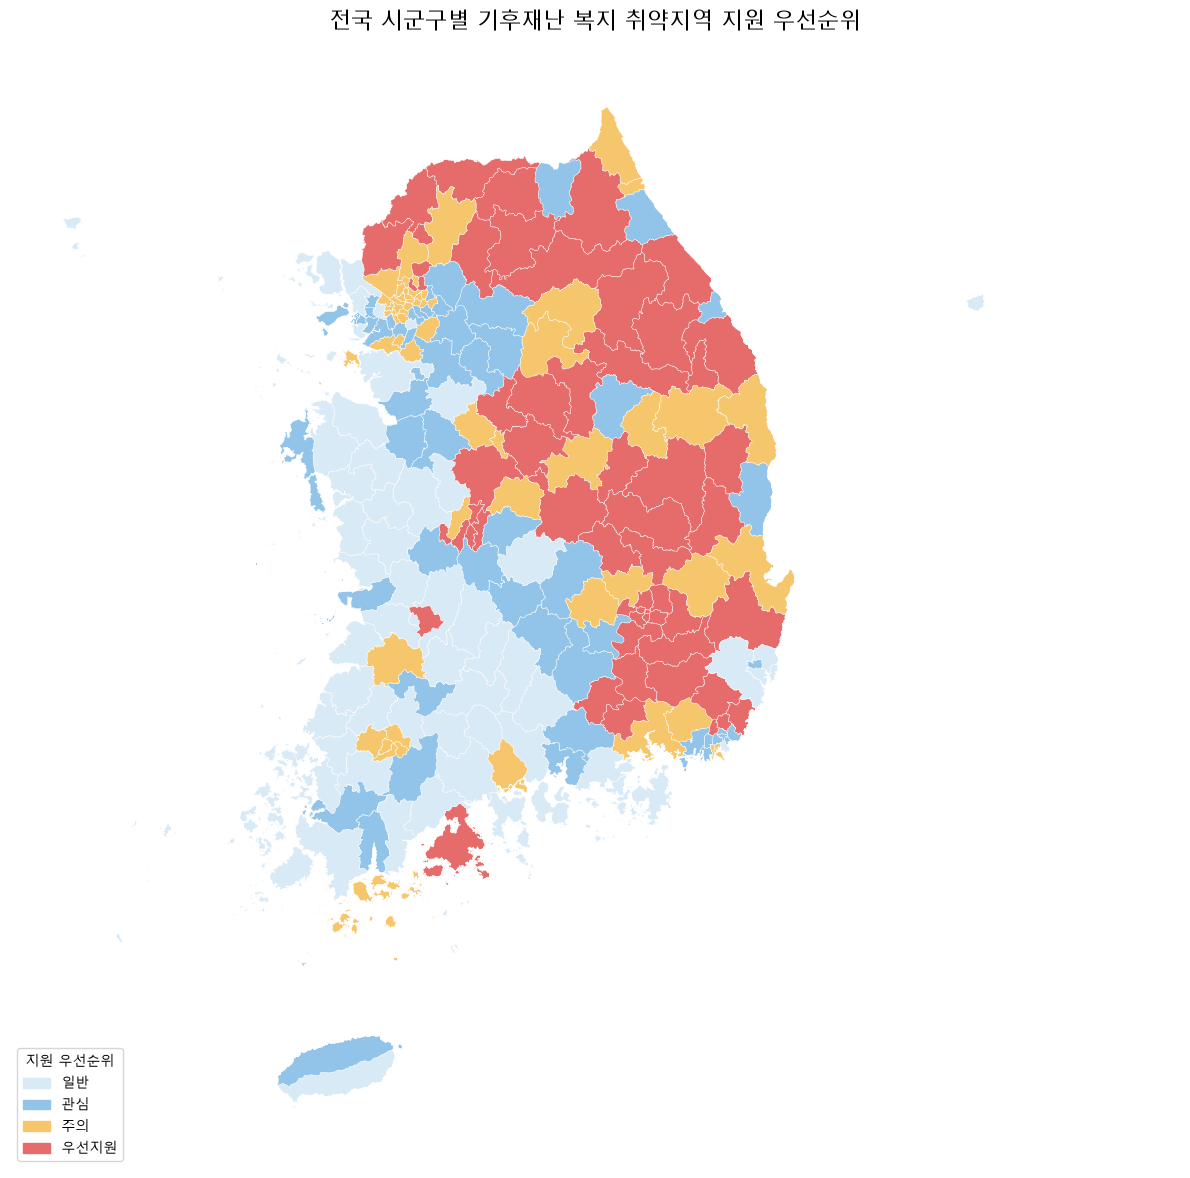

In [60]:
# 등급별 색상
grade_colors = {
    '일반': '#D9EAF7',
    '관심': '#91C4E8',
    '주의': '#F5C66B',
    '우선지원': '#E66B6B'
}

fig, ax = plt.subplots(figsize=(12, 14))

gdf_map.plot(
    ax=ax,
    color=gdf_map['지원_우선순위_등급'].map(grade_colors),
    edgecolor='white',
    linewidth=0.3
)

# 범례
handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=grade)
    for grade, color in grade_colors.items()
]

ax.legend(handles=handles, title='지원 우선순위',
          loc='lower left', fontsize=10)

ax.set_title(
    '전국 시군구별 기후재난 복지 취약지역 지원 우선순위',
    fontsize=16,
    pad=20
)

ax.axis('off')
plt.tight_layout()
plt.show()

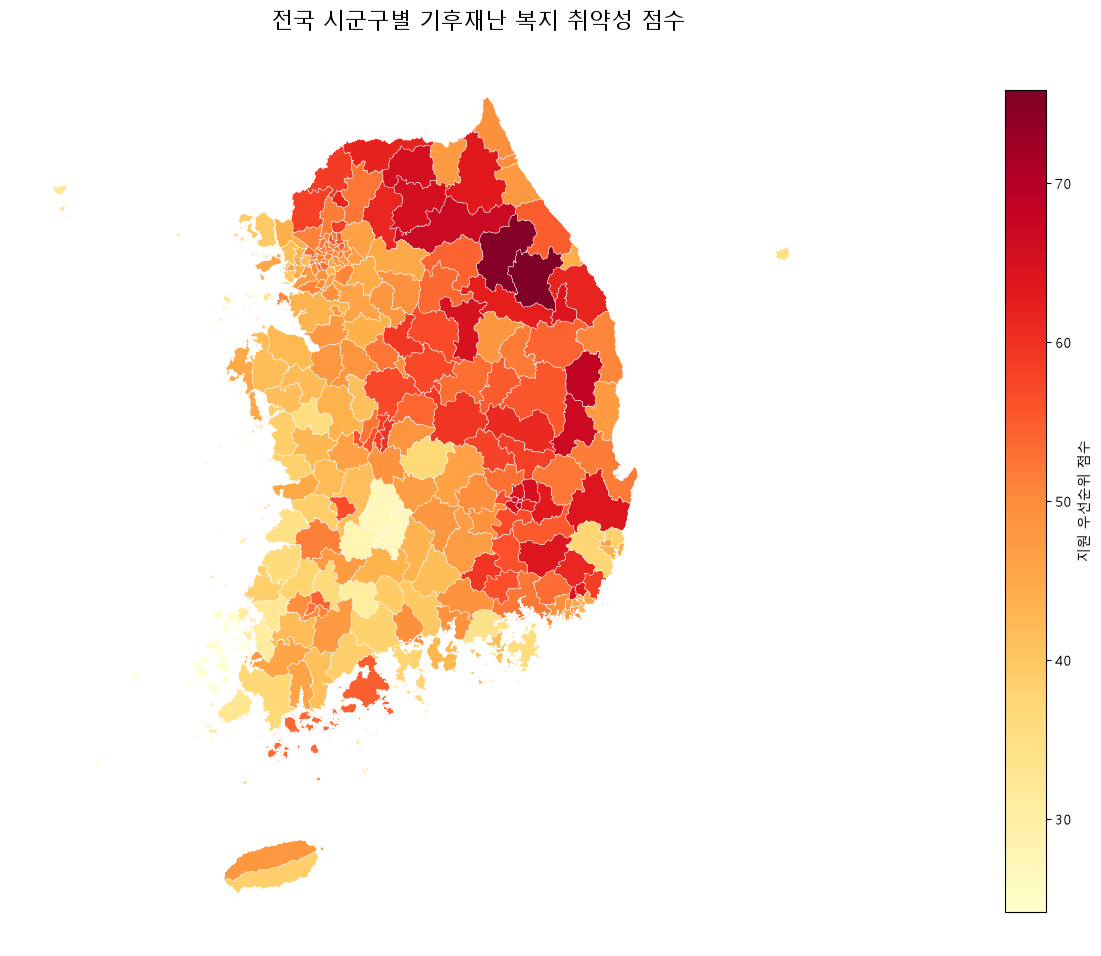

In [61]:
fig, ax = plt.subplots(figsize=(12, 14))

gdf_map.plot(
    column='지원_우선순위_점수',
    cmap='YlOrRd',
    linewidth=0.3,
    edgecolor='white',
    legend=True,
    legend_kwds={
        'label': '지원 우선순위 점수',
        'shrink': 0.6
    },
    ax=ax
)

ax.set_title(
    '전국 시군구별 기후재난 복지 취약성 점수',
    fontsize=16,
    pad=20
)

ax.axis('off')
plt.tight_layout()
plt.show()

In [62]:
top10_map = (
    gdf_map
    .sort_values('지원_우선순위_점수', ascending=False)
    .head(10)
    [['시도', '시군구_통합',
      '지원_우선순위_점수', '지원_우선순위_등급']]
)

display(top10_map)

,시도,시군구_통합,지원_우선순위_점수,지원_우선순위_등급
10,강원특별자치도,정선군,75.855059,우선지원
14,강원특별자치도,평창군,75.307408,우선지원
78,경상북도,영양군,68.880152,우선지원
90,대구광역시,남구,68.452056,우선지원
15,강원특별자치도,홍천군,67.054053,우선지원
95,대구광역시,서구,66.858481,우선지원
86,경상북도,청송군,66.830930,우선지원
93,대구광역시,동구,65.720190,우선지원
12,강원특별자치도,춘천시,65.716200,우선지원
16,강원특별자치도,화천군,65.560167,우선지원


In [63]:
top10_detail = (
    gdf_map
    .sort_values('지원_우선순위_점수', ascending=False)
    .head(10)
    [[
        '시도',
        '시군구_통합',
        '지원_우선순위_점수',
        '군집',
        '노인_1인가구_비율',
        '폭염일수',
        '한파일수',
        '무더위쉼터_비율',
        '한파쉼터_비율'
    ]]
)

display(top10_detail)

,시도,시군구_통합,지원_우선순위_점수,군집,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
10,강원특별자치도,정선군,75.855059,0,0.747983,0.738318,0.620253,0.094593,0.109998
14,강원특별자치도,평창군,75.307408,0,0.684064,0.738318,0.620253,0.068972,0.086904
78,경상북도,영양군,68.880152,0,0.838945,0.785047,0.468354,0.301467,0.314118
90,대구광역시,남구,68.452056,2,0.738113,0.943925,0.025316,0.011918,0.024165
15,강원특별자치도,홍천군,67.054053,0,0.603673,0.495327,0.607595,0.078112,0.094719
95,대구광역시,서구,66.858481,2,0.663882,0.943925,0.025316,0.033487,0.009860
86,경상북도,청송군,66.830930,0,0.752769,0.785047,0.468354,0.308895,0.328403
93,대구광역시,동구,65.720190,2,0.588553,0.943925,0.025316,0.008954,0.009840
12,강원특별자치도,춘천시,65.716200,0,0.506889,0.532710,0.575949,0.080966,0.061572
16,강원특별자치도,화천군,65.560167,0,0.666091,0.556075,0.835443,0.427929,0.408711


In [64]:
raw_cols = [
    '시도', '시군구',
    '노인_1인가구_비율',
    '폭염일수',
    '한파일수',
    '무더위쉼터_비율',
    '한파쉼터_비율'
]

top10_raw = (
    top10_detail[['시도', '시군구_통합']]
    .merge(
        df_mean[raw_cols],
        left_on=['시도', '시군구_통합'],
        right_on=['시도', '시군구'],
        how='left'
    )
    .drop(columns='시군구')
)

display(top10_raw)

,시도,시군구_통합,노인_1인가구_비율,폭염일수,한파일수,무더위쉼터_비율,한파쉼터_비율
0,강원특별자치도,정선군,27.138378,31.6,19.6,4.403579,4.315508
1,강원특별자치도,평창군,25.949386,31.6,19.6,3.469761,3.469761
2,경상북도,영양군,28.830429,33.6,14.8,11.943772,11.790647
3,대구광역시,남구,26.954782,40.4,0.8,1.390237,1.172160
4,강원특별자치도,홍천군,24.453980,21.2,19.2,3.802888,3.755939
5,대구광역시,서구,25.573965,40.4,0.8,2.176389,0.648286
6,경상북도,청송군,27.227408,33.6,14.8,12.214499,12.313803
7,대구광역시,동구,24.172722,40.4,0.8,1.282201,0.647576
8,강원특별자치도,춘천시,22.653632,22.8,18.2,3.906916,2.542055
9,강원특별자치도,화천군,25.615060,23.8,26.4,16.553067,15.254787


In [65]:
import os

output_path = '../data/processed'
os.makedirs(output_path, exist_ok=True)

# 우선순위 분석 결과
df_priority.to_csv(
    os.path.join(output_path, '지역별_지원우선순위.csv'),
    index=False,
    encoding='utf-8-sig'
)

# 지도 데이터
gdf_map.drop(columns='geometry').to_csv(
    os.path.join(output_path, '지역별_지도데이터.csv'),
    index=False,
    encoding='utf-8-sig'
)

print('분석 결과 CSV 저장 완료')

분석 결과 CSV 저장 완료


In [66]:
# 지도 경계와 분석 결과를 포함한 GeoJSON 저장
geojson_path = os.path.join(
    output_path,
    '지역별_지원우선순위_지도.geojson'
)

gdf_map.to_file(
    geojson_path,
    driver='GeoJSON',
    encoding='utf-8'
)

print('GeoJSON 저장 완료:', geojson_path)

GeoJSON 저장 완료: ../data/processed\지역별_지원우선순위_지도.geojson


In [69]:

from pathlib import Path

# 프로젝트 최상위 경로
BASE_DIR = Path.cwd().parent

# 군집 분석 결과 저장
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df_mean.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(f"저장 완료: {OUTPUT_PATH}")
print("폭염일수 평균:", df_mean["폭염일수"].mean())
print("한파일수 평균:", df_mean["한파일수"].mean())
print("무더위쉼터 비율 평균:", df_mean["무더위쉼터_비율"].mean())
print("한파쉼터 비율 평균:", df_mean["한파쉼터_비율"].mean())


저장 완료: c:\Users\expri\Desktop\SafeWeather-AI\data\processed\지역별_군집분석.csv
폭염일수 평균: 21.024454148471616
한파일수 평균: 4.628820960698689
무더위쉼터 비율 평균: 9.891432087925285
한파쉼터 비율 평균: 9.043783988389182
